# P3 — Supply Chain Demand Forecasting with Neural Networks
**Deliverables:** MLP regressor, Random Forest baseline, random-search tuning and validation curves.

In [26]:
!pip -q install scikit-learn matplotlib

In [27]:
from pathlib import Path
import os
DATA_DIR = Path("/kaggle/input/datasets/babblu123/real-world-ml-genai-kaggle-complete/real_world_ml_genai_lab/datasets")
if not DATA_DIR.exists():
    DATA_DIR = Path("../datasets")
if not DATA_DIR.exists():
    DATA_DIR = Path("datasets")
print("Dataset directory:", DATA_DIR.resolve())

import pandas as pd, numpy as np, matplotlib.pyplot as plt
df=pd.read_csv(DATA_DIR/"p3_supply_demand.csv",parse_dates=["date"])
df["day_of_year"]=df.date.dt.dayofyear; df["day_of_week"]=df.date.dt.dayofweek
df.head()

Dataset directory: /kaggle/input/datasets/babblu123/real-world-ml-genai-kaggle-complete/real_world_ml_genai_lab/datasets


,date,sku_id,promotion,discount_pct,regional_weather_index,shipping_delay_days,price,orders,day_of_year,day_of_week
0,2023-01-01,SKU0097,0,0.0,16.07,5,34.38,23,1,6
1,2023-01-02,SKU0025,0,0.0,23.24,2,67.30,15,2,0
2,2023-01-03,SKU0047,0,0.0,8.65,3,24.59,25,3,1
3,2023-01-04,SKU0090,0,0.0,28.20,3,13.06,23,4,2
4,2023-01-05,SKU0058,1,26.6,31.12,2,13.67,61,5,3


In [28]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
features=["sku_id","promotion","discount_pct","regional_weather_index","shipping_delay_days","price","day_of_year","day_of_week"]
X=df[features]; y=df.orders
# Time-aware split: do not shuffle future dates into training.
order=np.argsort(df.date.values); cut=int(len(order)*.8); tr,te=order[:cut],order[cut:]
prep=ColumnTransformer([("num",Pipeline([("impute",SimpleImputer()),("scale",StandardScaler())]),[c for c in features if c!="sku_id"]),("sku",OneHotEncoder(handle_unknown="ignore"),["sku_id"])])
mlp=Pipeline([("prep",prep),("model",MLPRegressor(max_iter=300,early_stopping=True,random_state=42))])
params={"model__hidden_layer_sizes":[(32,16),(64,32),(64,32,16)],"model__alpha":[.0001,.001,.01],"model__learning_rate_init":[.001,.01],"model__activation":["relu","tanh"]}
search=RandomizedSearchCV(mlp,params,n_iter=8,scoring="neg_mean_absolute_error",cv=3,random_state=42,n_jobs=-1)
search.fit(X.iloc[tr],y.iloc[tr]); pred=search.predict(X.iloc[te])
print("Best params:",search.best_params_,"MAE:",mean_absolute_error(y.iloc[te],pred),"RMSE:",mean_squared_error(y.iloc[te],pred)**.5)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

Best params: {'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (32, 16), 'model__alpha': 0.01, 'model__activation': 'relu'} MAE: 5.673393194428223 RMSE: 7.120959144995524


Random Forest MAE: 5.230467500257678 RMSE: 6.4581784456035285


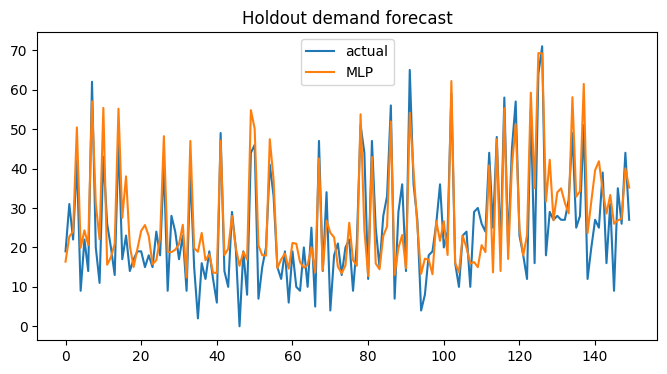

In [29]:
rf=Pipeline([("prep",prep),("model",RandomForestRegressor(n_estimators=200,min_samples_leaf=2,n_jobs=-1,random_state=42))])
rf.fit(X.iloc[tr],y.iloc[tr]); rfp=rf.predict(X.iloc[te])
print("Random Forest MAE:",mean_absolute_error(y.iloc[te],rfp),"RMSE:",mean_squared_error(y.iloc[te],rfp)**.5)
plt.figure(figsize=(8,4)); plt.plot(y.iloc[te].values[:150],label="actual"); plt.plot(pred[:150],label="MLP"); plt.legend(); plt.title("Holdout demand forecast"); plt.show()

## Notes
The dataset is synthetic. The time-aware split prevents training on later dates and testing on earlier dates. Explain forecast error and limits of simulated demand.